In [1]:

# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# CARREGAMENTO DOS DADOS
df = sns.load_dataset('diamonds')

# CONFERÊNCIA DO DATASET
print("Dimensões do dataset:", df.shape)

print("\nPrimeiras linhas:")
display(df.head())

print("\nTipos de dados:")
print(df.dtypes)


Dimensões do dataset: (53940, 10)

Primeiras linhas:


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75



Tipos de dados:
carat       float64
cut        category
color      category
clarity    category
depth       float64
table       float64
price         int64
x           float64
y           float64
z           float64
dtype: object


In [3]:

# ESTATÍSTICAS DESCRITIVAS E VALORES IMPOSSÍVEIS

colunas_numericas = df.select_dtypes(include=[np.number]).columns

print("Estatísticas descritivas:")
display(df[colunas_numericas].describe().round(2))

print("\nQuantidade de valores iguais a zero:")
print((df[colunas_numericas] == 0).sum())

print("\nQuantidade de valores negativos:")
print((df[colunas_numericas] < 0).sum())

print("\nValores ausentes:")
print(df[colunas_numericas].isna().sum())

print("\nRegistros com dimensões impossíveis (x, y ou z <= 0):")
dimensoes_invalidas = df[
    (df['x'] <= 0) |
    (df['y'] <= 0) |
    (df['z'] <= 0)
]

print("Quantidade:", len(dimensoes_invalidas))
display(dimensoes_invalidas.head())


Estatísticas descritivas:


,carat,depth,table,price,x,y,z
count,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00
mean,0.80,61.75,57.46,3932.80,5.73,5.73,3.54
std,0.47,1.43,2.23,3989.44,1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5324.25,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80



Quantidade de valores iguais a zero:
carat     0
depth     0
table     0
price     0
x         8
y         7
z        20
dtype: int64

Quantidade de valores negativos:
carat    0
depth    0
table    0
price    0
x        0
y        0
z        0
dtype: int64

Valores ausentes:
carat    0
depth    0
table    0
price    0
x        0
y        0
z        0
dtype: int64

Registros com dimensões impossíveis (x, y ou z <= 0):
Quantidade: 20


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0


In [4]:

# DETECÇÃO — Z-SCORE

colunas_numericas = df.select_dtypes(include=[np.number]).columns

# Calcula o Z-score de cada coluna numérica
z_scores = (
    (df[colunas_numericas] - df[colunas_numericas].mean())
    / df[colunas_numericas].std()
)

# Marca valores com Z-score maior que 3 ou menor que -3
mascara_zscore = z_scores.abs() > 3

print("Quantidade de outliers por coluna (Z-score):")
print(mascara_zscore.sum())

# Quantidade de registros com pelo menos um outlier
registros_outliers_z = mascara_zscore.any(axis=1)

print(
    "\nRegistros com pelo menos um outlier:",
    registros_outliers_z.sum()
)


Quantidade de outliers por coluna (Z-score):
carat     439
depth     685
table     336
price    1206
x          43
y          34
z          55
dtype: int64

Registros com pelo menos um outlier: 2350


In [5]:

# DETECÇÃO — IQR

Q1 = df[colunas_numericas].quantile(0.25)
Q3 = df[colunas_numericas].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

mascara_iqr = (
    (df[colunas_numericas] < limite_inferior) |
    (df[colunas_numericas] > limite_superior)
)

print("Quantidade de outliers por coluna (IQR):")
print(mascara_iqr.sum())

registros_outliers_iqr = mascara_iqr.any(axis=1)

print(
    "\nRegistros com pelo menos um outlier:",
    registros_outliers_iqr.sum()
)

print("\nComparação: Z-score x IQR")
comparacao_outliers = pd.DataFrame({
    'Z-score': mascara_zscore.sum(),
    'IQR': mascara_iqr.sum()
})

display(comparacao_outliers)


Quantidade de outliers por coluna (IQR):
carat    1889
depth    2545
table     605
price    3540
x          32
y          29
z          49
dtype: int64

Registros com pelo menos um outlier: 6416

Comparação: Z-score x IQR


,Z-score,IQR
carat,439,1889
depth,685,2545
table,336,605
price,1206,3540
x,43,32
y,34,29
z,55,49


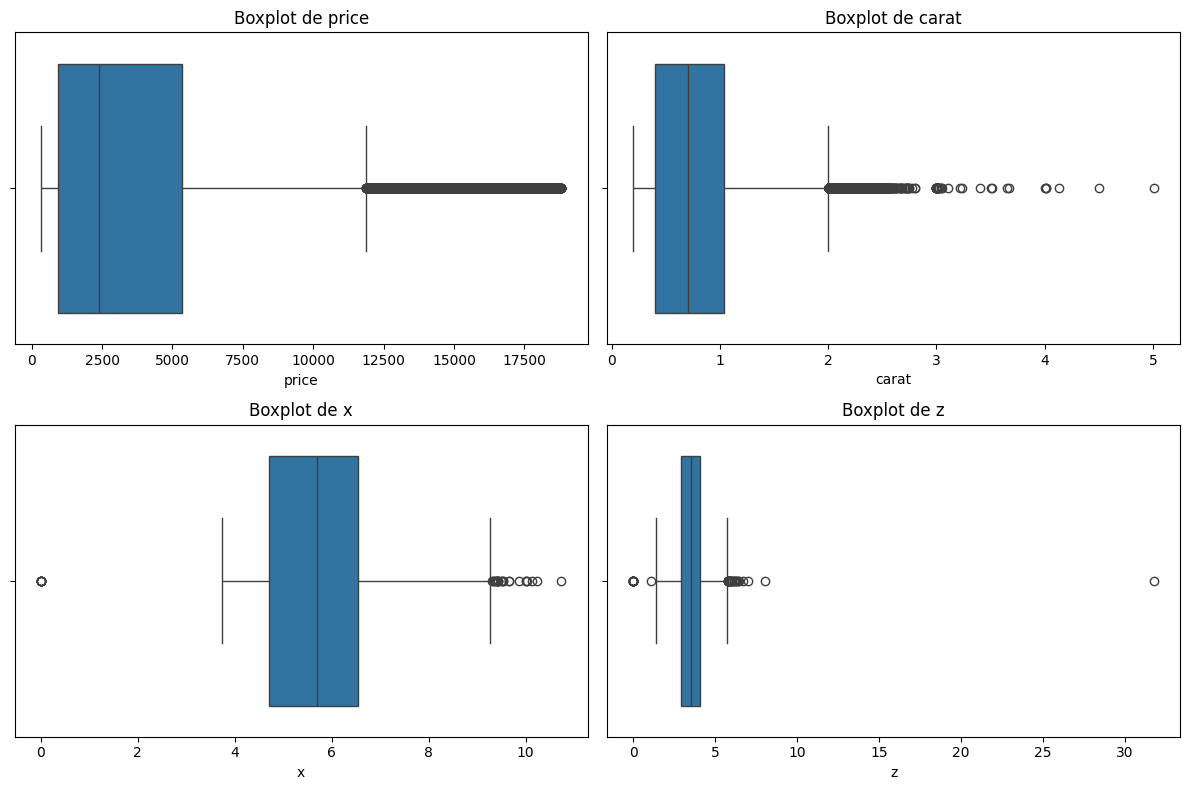

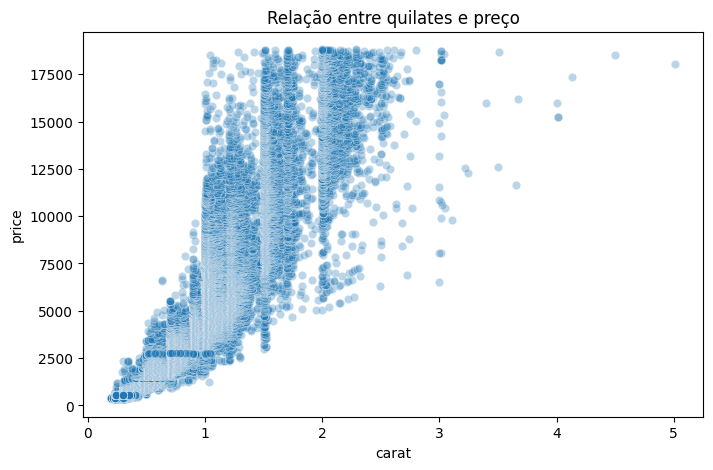

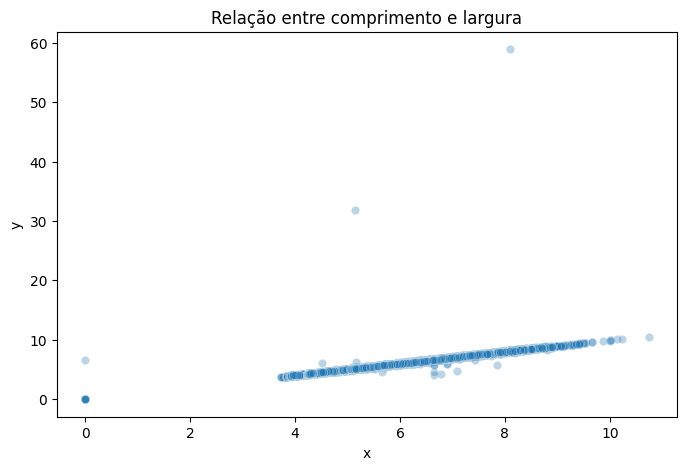

In [6]:

# VISUALIZAÇÕES

# Boxplots das principais variáveis numéricas
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, coluna in zip(axes.flatten(), ['price', 'carat', 'x', 'z']):
    sns.boxplot(data=df, x=coluna, ax=ax)
    ax.set_title(f'Boxplot de {coluna}')

plt.tight_layout()
plt.show()

# Dispersão: quilates x preço
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='carat', y='price', alpha=0.3)
plt.title('Relação entre quilates e preço')
plt.show()

# Dispersão: comprimento x largura
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='x', y='y', alpha=0.3)
plt.title('Relação entre comprimento e largura')
plt.show()


In [7]:

# ERRO x VALOR EXTREMO LEGÍTIMO

# Dimensões iguais a zero ou negativas
dimensoes_invalidas = df[
    (df['x'] <= 0) |
    (df['y'] <= 0) |
    (df['z'] <= 0)
]

print("Registros com dimensões impossíveis:", len(dimensoes_invalidas))
display(dimensoes_invalidas.head(10))

# Diamantes com mais de 4 quilates
diamantes_raros = df[df['carat'] > 4]

print("\nDiamantes com mais de 4 quilates:", len(diamantes_raros))
display(diamantes_raros[['carat', 'price', 'x', 'y', 'z']].head(10))

# Maiores preços
print("\n10 diamantes com maiores preços:")
display(df.nlargest(10, 'price')[['carat', 'price', 'cut', 'color', 'clarity']])


Registros com dimensões impossíveis: 20


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0



Diamantes com mais de 4 quilates: 5


,carat,price,x,y,z
25998,4.01,15223,10.14,10.10,6.17
25999,4.01,15223,10.02,9.94,6.24
27130,4.13,17329,10.00,9.85,6.43
27415,5.01,18018,10.74,10.54,6.98
27630,4.50,18531,10.23,10.16,6.72



10 diamantes com maiores preços:


,carat,price,cut,color,clarity
27749,2.29,18823,Premium,I,VS2
27748,2.00,18818,Very Good,G,SI1
27747,1.51,18806,Ideal,G,IF
27746,2.07,18804,Ideal,G,SI2
27745,2.00,18803,Very Good,H,SI1
27744,2.29,18797,Premium,I,SI1
27742,2.04,18795,Premium,H,SI1
27743,2.00,18795,Premium,I,VS1
27740,1.71,18791,Premium,F,VS2
27741,2.15,18791,Ideal,G,SI2


In [8]:

# TRATAMENTO — REMOÇÃO / CAPPING / TRANSFORMAÇÃO

# Limites IQR para price
q1_price = df['price'].quantile(0.25)
q3_price = df['price'].quantile(0.75)
iqr_price = q3_price - q1_price

limite_inf_price = q1_price - 1.5 * iqr_price
limite_sup_price = q3_price + 1.5 * iqr_price

# 1. Remoção dos outliers de price
df_remocao = df[
    (df['price'] >= limite_inf_price) &
    (df['price'] <= limite_sup_price)
].copy()

# 2. Capping: substituição dos valores fora dos limites
df_capping = df.copy()
df_capping['price'] = df_capping['price'].clip(
    lower=limite_inf_price,
    upper=limite_sup_price
)

# 3. Transformação logarítmica de price
df_log = df.copy()
df_log['price_log'] = np.log1p(df_log['price'])

print("Linhas originais:", len(df))
print("Linhas após remoção:", len(df_remocao))
print("Linhas removidas:", len(df) - len(df_remocao))

print("\nPreços após capping:")
display(df_capping['price'].describe().to_frame().round(2))

print("\nPreços transformados com log1p:")
display(df_log['price_log'].describe().to_frame().round(2))


Linhas originais: 53940
Linhas após remoção: 50400
Linhas removidas: 3540

Preços após capping:


,price
count,53940.00
mean,3732.15
std,3436.77
min,326.00
25%,950.00
50%,2401.00
75%,5324.25
max,11885.62



Preços transformados com log1p:


,price_log
count,53940.00
mean,7.79
std,1.01
min,5.79
25%,6.86
50%,7.78
75%,8.58
max,9.84


,Original,Remoção,Capping,Log1p
count,53940.00,50400.00,53940.00,53940.00
mean,3932.80,3159.46,3732.15,7.79
std,3989.44,2764.70,3436.77,1.01
min,326.00,326.00,326.00,5.79
25%,950.00,911.00,950.00,6.86
50%,2401.00,2155.00,2401.00,7.78
75%,5324.25,4669.00,5324.25,8.58
max,18823.00,11883.00,11885.62,9.84


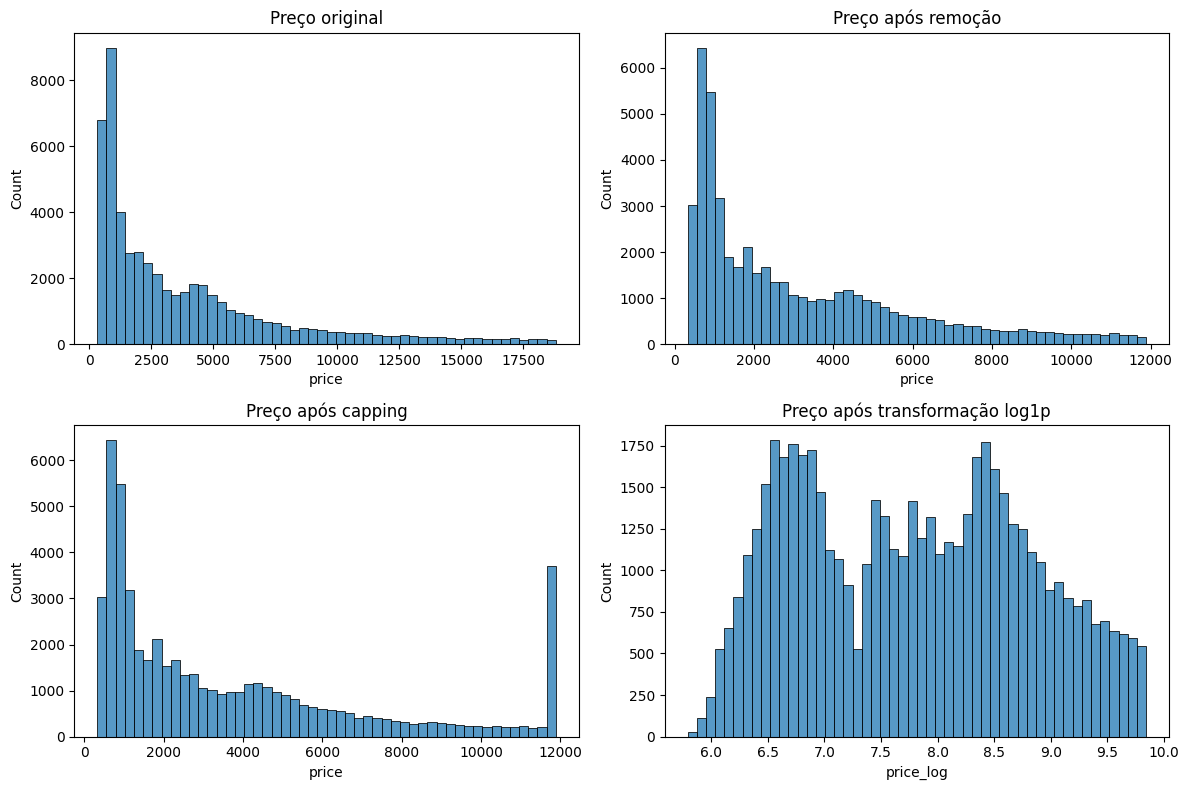

In [9]:

# COMPARAÇÃO ENTRE AS ESTRATÉGIAS

comparacao_tratamentos = pd.DataFrame({
    'Original': df['price'].describe(),
    'Remoção': df_remocao['price'].describe(),
    'Capping': df_capping['price'].describe(),
    'Log1p': df_log['price_log'].describe()
})

display(comparacao_tratamentos.round(2))

# Comparação das distribuições de preço
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df['price'], bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Preço original')

sns.histplot(df_remocao['price'], bins=50, ax=axes[0, 1])
axes[0, 1].set_title('Preço após remoção')

sns.histplot(df_capping['price'], bins=50, ax=axes[1, 0])
axes[1, 0].set_title('Preço após capping')

sns.histplot(df_log['price_log'], bins=50, ax=axes[1, 1])
axes[1, 1].set_title('Preço após transformação log1p')

plt.tight_layout()
plt.show()


Text(0, 0.5, 'Frequência')

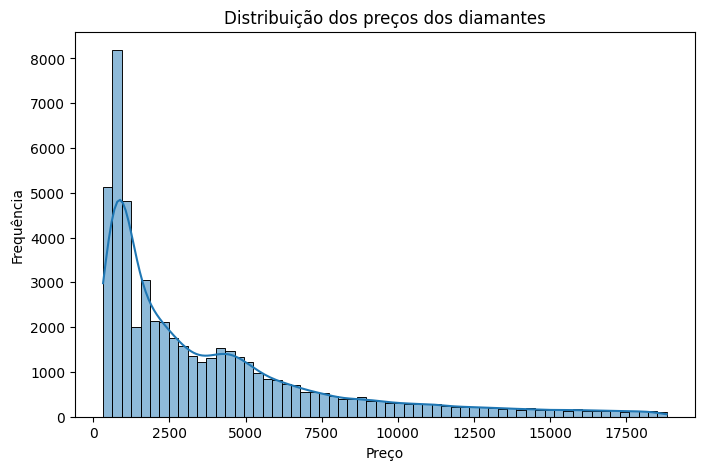

In [10]:
# 1. O Z-score parte de qual suposição? Ela vale para price?
#
# O Z-score é mais adequado quando os dados têm distribuição aproximadamente
# normal, simétrica e em formato de sino. A coluna price não segue bem esse
# padrão, pois apresenta assimetria à direita: muitos diamantes têm preços
# menores e poucos têm preços muito elevados. Isso pode influenciar a
# identificação de outliers pelo Z-score.

# Gráfico para verificar a distribuição de price
plt.figure(figsize=(8, 5))
sns.histplot(df['price'], bins=60, kde=True)
plt.title('Distribuição dos preços dos diamantes')
plt.xlabel('Preço')
plt.ylabel('Frequência')